In [1]:
!pip install qiskit qiskit-aer matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 20.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 55.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 39.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import qasm2, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

In [3]:
# The four input states used in the paper
PREP = {
    "+Z": "",                    # |0>
    "-Z": "x q[1];",             # |1>
    "+X": "h q[1];",             # |+>
    "+Y": "h q[1];\ns q[1];",    # |+i>
}

def build_qasm(prep="+Z", theta=0.0, mode="toffoli", error_qubits=(0, 1, 2), measure=False):
    """
    mode = "none"        -> no QEC: error rz(theta) applied only to Q2 (paper's comparison case)
    mode = "decode_only" -> encode + error + decode, but no correction
    mode = "toffoli"     -> full base-paper scheme with CCNOT correction
    mode = "feedforward" -> EXTENSION: measure ancillas, then apply X to Q2 only if syndrome = 11
    """
    L = ["OPENQASM 2.0;", 'include "qelib1.inc";', "qreg q[3];", "creg c[3];"]
    if mode == "feedforward":
        L.append("creg syn[2];")          # separate register that stores the syndrome
    if PREP[prep]:
        L.append(PREP[prep])
    if mode == "none":
        L.append(f"rz({theta}) q[1];")
    else:
        # ENCODE
        L += ["ry(pi/2) q[0];", "ry(pi/2) q[2];",
              "cz q[1],q[0];", "cz q[1],q[2];",
              "ry(pi/2) q[1];",
              "barrier q;"]
        # ERROR
        L += [f"rz({theta}) q[{k}];" for k in error_qubits]
        # DECODE
        L += ["barrier q;",
              "ry(-pi/2) q[1];",
              "cz q[1],q[0];", "cz q[1],q[2];",
              "ry(-pi/2) q[0];", "ry(-pi/2) q[2];"]
        # CORRECT
        if mode == "toffoli":
            L.append("ccx q[0],q[2],q[1];")
        elif mode == "feedforward":
            L += ["measure q[0] -> syn[0];",      # read ancilla Q1
                  "measure q[2] -> syn[1];",      # read ancilla Q3
                  "if(syn==3) x q[1];"]           # syndrome 11 -> flip Q2
    if measure:
        L.append("measure q -> c;")
    return "\n".join(L)

In [4]:
!pip install pylatexenc

In [5]:
import numpy as np
from qiskit import qasm2

OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
creg c[3];
ry(pi/2) q[0];
ry(pi/2) q[2];
cz q[1],q[0];
cz q[1],q[2];
ry(pi/2) q[1];
barrier q;
rz(1.0471975511965976) q[0];
rz(1.0471975511965976) q[1];
rz(1.0471975511965976) q[2];
barrier q;
ry(-pi/2) q[1];
cz q[1],q[0];
cz q[1],q[2];
ry(-pi/2) q[0];
ry(-pi/2) q[2];
ccx q[0],q[2],q[1];


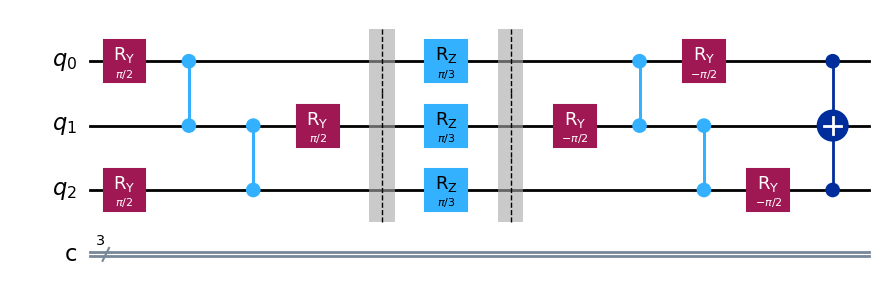

In [6]:
qasm_text = build_qasm(prep="+Z", theta=np.pi/3, mode="toffoli")

print(qasm_text)

qc = qasm2.loads(qasm_text)

qc.draw(output="mpl")

In [7]:
sim_counts = AerSimulator()
print(f"{'Error on':<10}{'No correction':<18}{'Toffoli':<18}{'Feed-forward':<18}")
for name, qubits in [("none", ()), ("Q1", (0,)), ("Q2", (1,)), ("Q3", (2,))]:
    row = []
    for mode in ["decode_only", "toffoli", "feedforward"]:
        qc = qasm2.loads(build_qasm("-Z", np.pi, mode, qubits, measure=True))
        counts = sim_counts.run(qc, shots=1024).result().get_counts()
        # keep only the final 3-qubit register c (drop the syndrome register printed first)
        counts = {k.split()[-1]: v for k, v in counts.items()}
        row.append(counts)
    print(f"{name:<10}{str(row[0]):<18}{str(row[1]):<18}{str(row[2]):<18}")

Error on  No correction     Toffoli           Feed-forward      
none      {'010': 1024}     {'010': 1024}     {'010': 1024}     
Q1        {'011': 1024}     {'011': 1024}     {'011': 1024}     
Q2        {'101': 1024}     {'111': 1024}     {'111': 1024}     
Q3        {'110': 1024}     {'110': 1024}     {'110': 1024}     


In [8]:
def rho_q2(prep, theta, mode, noise=None, shots=2000):
    """Final density matrix of Q2 (no tomography needed in simulation).
    noise = None -> ideal simulator; otherwise a qiskit-aer NoiseModel."""
    qc = qasm2.loads(build_qasm(prep, theta, mode))
    qc = transpile(qc, basis_gates=["u3", "cx"], optimization_level=0)   # real hardware gates
    qc.save_density_matrix(qubits=[1])
    sim = AerSimulator(method="density_matrix", noise_model=noise)
    # feed-forward contains a measurement -> average over many shots;
    # other modes have no measurement, so a single run is already exact
    n = shots if mode == "feedforward" else 1
    return np.asarray(sim.run(qc, shots=n).result().data()["density_matrix"])

def process_fidelity(theta, mode, noise=None):
    r0, r1, rX, rY = (rho_q2(s, theta, mode, noise) for s in ["+Z", "-Z", "+X", "+Y"])
    # Rebuild how the process acts on |i><j| (Nielsen & Chuang, Box 8.5)
    E = {(0, 0): r0,
         (1, 1): r1,
         (0, 1): rX + 1j*rY - (1+1j)*(r0 + r1)/2,
         (1, 0): rX - 1j*rY - (1-1j)*(r0 + r1)/2}
    # Process fidelity with the identity (ideal = "nothing happened to Q2")
    return float(np.real(sum(E[(i, j)][i, j] for i in range(2) for j in range(2)) / 4))

In [9]:
print("No correction, no error :", process_fidelity(0.0, "none"))
print("Toffoli QEC,  no error :", process_fidelity(0.0, "toffoli"))
print("Feed-forward, no error :", process_fidelity(0.0, "feedforward"))

No correction, no error : 1.0
Toffoli QEC,  no error : 1.0
Feed-forward, no error : 1.0


In [10]:
p_values = np.linspace(0, 1, 41)
theta_values = 2*np.arcsin(np.sqrt(p_values))    # p = sin^2(theta/2)

F_none = np.array([process_fidelity(t, "none") for t in theta_values])
F_toff = np.array([process_fidelity(t, "toffoli") for t in theta_values])

for p, a, b in list(zip(p_values, F_none, F_toff))[::5]:
    print(f"p = {p:.3f}   no corr = {a:.4f}   Toffoli = {b:.4f}")

p = 0.000   no corr = 1.0000   Toffoli = 1.0000
p = 0.125   no corr = 0.8750   Toffoli = 0.9570
p = 0.250   no corr = 0.7500   Toffoli = 0.8438
p = 0.375   no corr = 0.6250   Toffoli = 0.6836
p = 0.500   no corr = 0.5000   Toffoli = 0.5000
p = 0.625   no corr = 0.3750   Toffoli = 0.3164
p = 0.750   no corr = 0.2500   Toffoli = 0.1563
p = 0.875   no corr = 0.1250   Toffoli = 0.0430
p = 1.000   no corr = 0.0000   Toffoli = -0.0000


In [11]:
c_none = np.polyfit(p_values, F_none, 1)[::-1]
c_toff = np.polyfit(p_values, F_toff, 3)[::-1]
print("No correction fit : f = %.3f %+.3f p" % tuple(c_none))
print("Toffoli fit       : f = %.3f %+.3f p %+.3f p^2 %+.3f p^3" % tuple(c_toff))

No correction fit : f = 1.000 -1.000 p
Toffoli fit       : f = 1.000 +0.000 p -3.000 p^2 +2.000 p^3


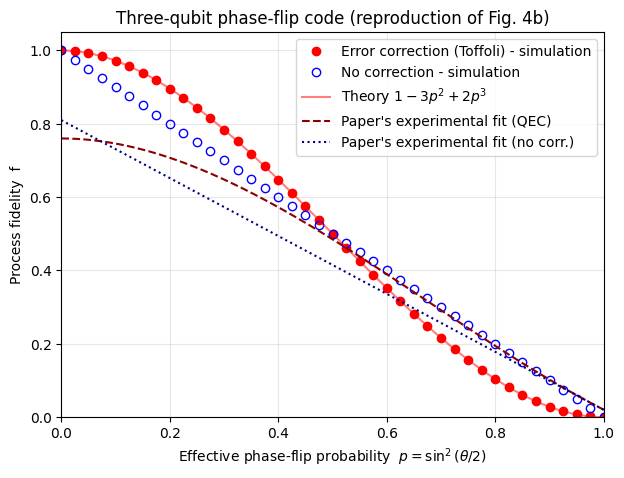

In [12]:
pp = np.linspace(0, 1, 200)
plt.figure(figsize=(7, 5))
plt.plot(p_values, F_toff, "o", color="red", label="Error correction (Toffoli) - simulation")
plt.plot(p_values, F_none, "o", mfc="none", color="blue", label="No correction - simulation")
plt.plot(pp, 1 - 3*pp**2 + 2*pp**3, "-", color="red", alpha=0.5, label=r"Theory $1-3p^2+2p^3$")
plt.plot(pp, 0.76 - 1.46*pp**2 + 0.72*pp**3, "--", color="darkred", label="Paper's experimental fit (QEC)")
plt.plot(pp, 0.81 - 0.79*pp, ":", color="navy", label="Paper's experimental fit (no corr.)")
plt.xlabel(r"Effective phase-flip probability  $p=\sin^2(\theta/2)$")
plt.ylabel("Process fidelity  f")
plt.title("Three-qubit phase-flip code (reproduction of Fig. 4b)")
plt.xlim(0, 1); plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.legend()
plt.show()

# Extension: measurement-based (feed-forward) correction

**Change made to the base paper:** the Toffoli (CCNOT) correction gate is replaced by

1. measuring the two ancillas (Q1, Q3) → 2-bit syndrome
2. applying `X` to Q2 **only if** the syndrome is `11`

The paper mentions this approach itself (it was too hard on 2011 hardware).

Two experiments:
* **A. Ideal simulator** — both methods should give the *same* curve (deferred measurement principle).
* **B. Minimal noise** — every 2-qubit (CNOT) gate gets a 2% depolarizing error. The Toffoli needs 6 extra CNOTs, the feed-forward needs none.

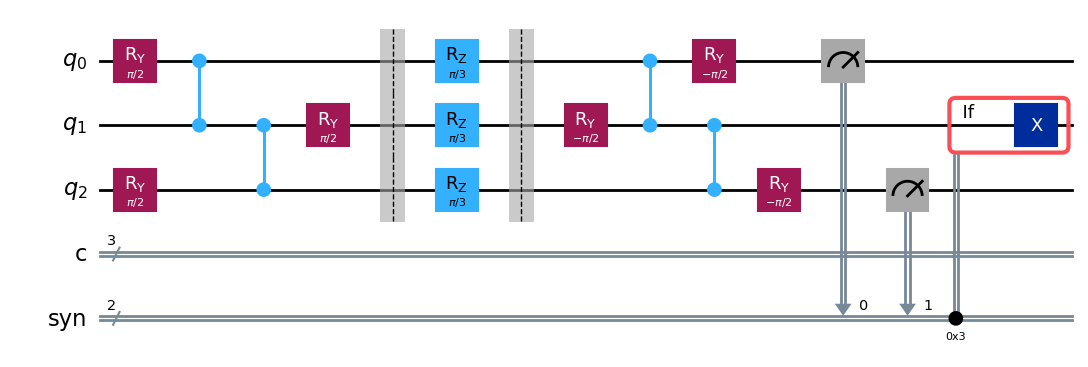

In [13]:
# EXTENSION: draw the measurement-based (feed-forward) circuit
qc_ff = qasm2.loads(build_qasm(prep="+Z", theta=np.pi/3, mode="feedforward"))
qc_ff.draw(output="mpl")

Feed-forward fit  : f = 0.999 +0.011 p -3.024 p^2 +2.013 p^3
Max |Toffoli - Feed-forward| = 0.0062


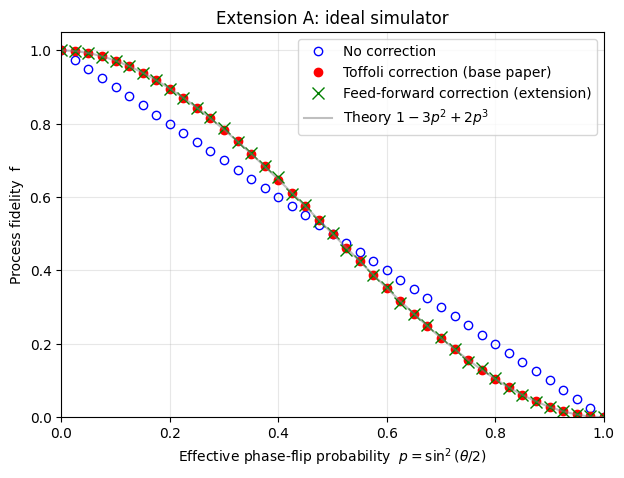

In [14]:
# EXTENSION A: ideal simulator - compare all three methods
F_ff = np.array([process_fidelity(t, "feedforward") for t in theta_values])

c_ff = np.polyfit(p_values, F_ff, 3)[::-1]
print("Feed-forward fit  : f = %.3f %+.3f p %+.3f p^2 %+.3f p^3" % tuple(c_ff))
print("Max |Toffoli - Feed-forward| =", round(float(np.max(np.abs(F_toff - F_ff))), 4))

plt.figure(figsize=(7, 5))
plt.plot(p_values, F_none, "o", mfc="none", color="blue", label="No correction")
plt.plot(p_values, F_toff, "o", color="red", label="Toffoli correction (base paper)")
plt.plot(p_values, F_ff, "x", color="green", ms=8, label="Feed-forward correction (extension)")
plt.plot(pp, 1 - 3*pp**2 + 2*pp**3, "-", color="gray", alpha=0.5, label=r"Theory $1-3p^2+2p^3$")
plt.xlabel(r"Effective phase-flip probability  $p=\sin^2(\theta/2)$")
plt.ylabel("Process fidelity  f")
plt.title("Extension A: ideal simulator")
plt.xlim(0, 1); plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.legend()
plt.show()

In [15]:
# EXTENSION B: minimal noise model
# Every CNOT (2-qubit gate) has a 2% chance of a random error.
noise = NoiseModel()
noise.add_all_qubit_quantum_error(depolarizing_error(0.02, 2), ["cx"])
print("Noise model: 2% depolarizing error on every CNOT gate")

# How many CNOTs does each method use? (this is WHY the results differ)
for mode in ["none", "toffoli", "feedforward"]:
    qc = transpile(qasm2.loads(build_qasm("+Z", 0.0, mode)), basis_gates=["u3", "cx"], optimization_level=0)
    print(f"{mode:<12} CNOT count = {qc.count_ops().get('cx', 0)}")

Noise model: 2% depolarizing error on every CNOT gate
none         CNOT count = 0
toffoli      CNOT count = 10
feedforward  CNOT count = 4


In [16]:
# EXTENSION B: noisy sweep (takes ~1-2 minutes)
p_noisy = np.linspace(0, 1, 21)
th_noisy = 2*np.arcsin(np.sqrt(p_noisy))

Fn_none = np.array([process_fidelity(t, "none", noise) for t in th_noisy])
Fn_toff = np.array([process_fidelity(t, "toffoli", noise) for t in th_noisy])
Fn_ff   = np.array([process_fidelity(t, "feedforward", noise) for t in th_noisy])

print(f"{'p':>6}{'No corr':>10}{'Toffoli':>10}{'Feed-fwd':>10}")
for p, a, b, c in list(zip(p_noisy, Fn_none, Fn_toff, Fn_ff))[::2]:
    print(f"{p:6.2f}{a:10.4f}{b:10.4f}{c:10.4f}")

     p   No corr   Toffoli  Feed-fwd
  0.00    1.0000    0.8924    0.9440
  0.10    0.9000    0.8677    0.9186
  0.20    0.8000    0.8022    0.8483
  0.30    0.7000    0.7060    0.7444
  0.40    0.6000    0.5895    0.6214
  0.50    0.5000    0.4627    0.4799
  0.60    0.4000    0.3359    0.3428
  0.70    0.3000    0.2193    0.2167
  0.80    0.2000    0.1232    0.1087
  0.90    0.1000    0.0577    0.0407
  1.00    0.0000    0.0330    0.0141


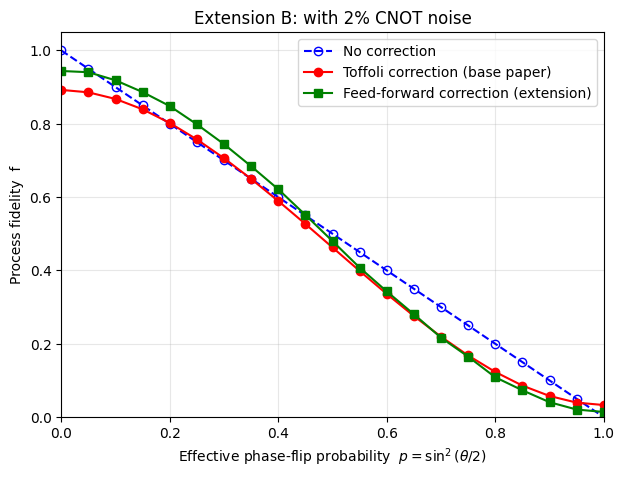

At p = 0 :  Toffoli = 0.892   Feed-forward = 0.944   -> improvement = +0.052


In [17]:
plt.figure(figsize=(7, 5))
plt.plot(p_noisy, Fn_none, "o--", mfc="none", color="blue", label="No correction")
plt.plot(p_noisy, Fn_toff, "o-", color="red", label="Toffoli correction (base paper)")
plt.plot(p_noisy, Fn_ff, "s-", color="green", label="Feed-forward correction (extension)")
plt.xlabel(r"Effective phase-flip probability  $p=\sin^2(\theta/2)$")
plt.ylabel("Process fidelity  f")
plt.title("Extension B: with 2% CNOT noise")
plt.xlim(0, 1); plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.legend()
plt.show()

print(f"At p = 0 :  Toffoli = {Fn_toff[0]:.3f}   Feed-forward = {Fn_ff[0]:.3f}   "
      f"-> improvement = {Fn_ff[0]-Fn_toff[0]:+.3f}")

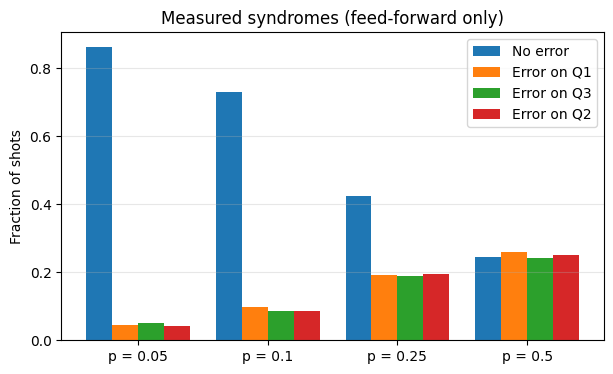

In [18]:
# EXTRA: only the feed-forward method tells us WHICH qubit had the error.
# Syndrome (Q3 Q1):  00 = no error,  01 = error on Q1,  10 = error on Q3,  11 = error on Q2
labels = {"00": "No error", "01": "Error on Q1", "10": "Error on Q3", "11": "Error on Q2"}
p_list = [0.05, 0.1, 0.25, 0.5]
table = {lab: [] for lab in labels.values()}
for p in p_list:
    t = 2*np.arcsin(np.sqrt(p))
    qc = qasm2.loads(build_qasm("+Z", t, "feedforward"))
    counts = sim_counts.run(qc, shots=4000).result().get_counts()
    syn = {}
    for k, v in counts.items():                  # key looks like "syn c" e.g. "11 000"
        s = k.split()[0]
        syn[s] = syn.get(s, 0) + v
    for s, lab in labels.items():
        table[lab].append(syn.get(s, 0) / 4000)

x = np.arange(len(p_list)); w = 0.2
plt.figure(figsize=(7, 4))
for i, (lab, vals) in enumerate(table.items()):
    plt.bar(x + (i-1.5)*w, vals, w, label=lab)
plt.xticks(x, [f"p = {p}" for p in p_list])
plt.ylabel("Fraction of shots"); plt.title("Measured syndromes (feed-forward only)")
plt.legend(); plt.grid(axis="y", alpha=0.3); plt.show()